# 4.1 ความจริงของจำนวนที่เพิ่มขึ้น — จำนวนกำลังคนและบริการ

**คำถามของหัวข้อนี้**
1. กำลังคนสี่วิชาชีพ (แพทย์ พยาบาลวิชาชีพ เภสัชกร ทันตแพทย์) เพิ่มขึ้นเท่าใด และเพิ่มขึ้นในสังกัดใด
2. สังกัดใดมีส่วนต่อการเพิ่มขึ้น **สุทธิ** มากที่สุด — ซึ่งอาจไม่ใช่สังกัดที่เติบโตเร็วที่สุด
3. บริการผู้ป่วยนอก ผู้ป่วยใน วันนอน และน้ำหนักบริการ (AdjRW/CMI) เปลี่ยนไปอย่างไร ในขอบเขตข้อมูลใด
4. ทำไมการเพิ่มขึ้นคู่ขนานของกำลังคนและบริการจึงยังไม่ใช่หลักฐานของความเพียงพอหรือดุลยภาพ

**ขอบเขต** ภาพรวมระดับประเทศ (รวมกรุงเทพมหานคร) พ.ศ. 2556–2568 สำหรับกำลังคนและบริการ
และปีงบประมาณ 2561–2568 สำหรับ case-mix — ตัวเลขทุกตัวในหัวข้อนี้มาจากตารางกลาง
`data/processed/` ที่สร้างโดย `python -m chapter4.build --shared` ไม่มีการพิมพ์ตัวเลขเอง

**วิธีรัน** Restart Kernel → Run All (ต้องสร้างข้อมูลกลางก่อน หากยังไม่มีจะได้ข้อความบอกคำสั่งที่ต้องรัน)

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "analysis.toml").exists())
sys.path.insert(0, str(_root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from chapter4 import config as C, panels as P, metrics as M, reporting as R
from chapter4.ingest import load

pd.options.display.max_columns = 40
pd.options.display.width = 200
FONT = R.setup_style()
S = R.Section("4_1")
Y0, Y1 = C.Y0, C.Y1
FY0, FY1 = C.CFG["years"]["casemix_first"], C.CFG["years"]["casemix_last"]
CAD = C.CADRES
SEC_TH = {"moph": "กระทรวงสาธารณสุข", "other_public": "ภาครัฐอื่น ๆ", "private": "เอกชน",
          "unclassified": "อื่น ๆ / ไม่จำแนก", "public_total": "ภาครัฐรวม", "all_sectors": "ทุกสังกัด"}
print("font:", FONT)
print(C.effective_config("4_1"))

font: Prompt
{
 "years": {
  "long_first": 2013,
  "long_last": 2025,
  "casemix_first": 2018,
  "casemix_last": 2025,
  "morbidity_first": 2022,
  "morbidity_last": 2025,
  "flow_first_fy": 2017,
  "flow_last_complete_fy": 2025,
  "recent_window_years": 5,
  "pre_transfer_last": 2022,
  "covid_years": [
   2020,
   2021,
   2022
  ]
 },
 "cadres": {
  "main": [
   "แพทย์",
   "พยาบาลวิชาชีพ",
   "เภสัชกร",
   "ทันตแพทย์"
  ],
  "diagnostic": [
   "พยาบาลเทคนิค"
  ],
  "combined_reference": [
   "แพทย์",
   "พยาบาลวิชาชีพ"
  ],
  "nurse_includes_technical": true,
  "en": {
   "แพทย์": "physicians",
   "พยาบาลวิชาชีพ": "professional_nurses",
   "เภสัชกร": "pharmacists",
   "ทันตแพทย์": "dentists",
   "พยาบาลเทคนิค": "technical_nurses"
  }
 },
 "sectors": {
  "MinistryofPublichealth": "moph",
  "OtherMinistries": "other_public",
  "StateEnterprises": "other_public",
  "IndependentOrganizations": "other_public",
  "LocalGovernment": "other_public",
  "LocalAdministration": "other_public",

## 1. ข้อมูลและนิยาม

กำลังคนมาจากรายงานทรัพยากรสาธารณสุข (ตารางที่ 11–14) เป็น **จำนวนคงอยู่ (stock) ณ ปีรายงาน**
นับเป็นคน (headcount) ไม่ใช่ FTE สังกัดถูกจัดเป็นหมวดที่ไม่ซ้อนกัน: กระทรวงสาธารณสุข ภาครัฐอื่น ๆ
(กระทรวงอื่น รัฐวิสาหกิจ หน่วยงานอิสระ ท้องถิ่น) เอกชน และ "อื่น ๆ" ที่แหล่งตีพิมพ์เฉพาะปี 2559–2561
ยอดรวมที่แหล่งตีพิมพ์ใช้ **ตรวจ** ผลรวมของหมวดย่อยเท่านั้น

**การตัดสินใจของผู้เขียน (26 ก.ย. 2569): ในหัวข้อ 4.1 "พยาบาลวิชาชีพ" = พยาบาลวิชาชีพ + พยาบาลเทคนิค** รวมรายสังกัด
แหล่งตีพิมพ์พยาบาลเทคนิคเป็นตารางแยกเฉพาะปี 2556–2564 หลังจากนั้นไม่มีหมวดนี้ จึงนับเป็นศูนย์ในปีที่ไม่ตีพิมพ์
การเพิ่มขึ้นของชุดรวมในปี 2565 ที่ต่ำกว่าพยาบาลวิชาชีพเพียงลำพังสอดคล้องกับการที่พยาบาลเทคนิคเดิมถูกนับรวมในพยาบาลวิชาชีพตั้งแต่ปี 2565
ชุดรวมจึงต่อเนื่องกว่า — ใช้นิยามเดียวกันทั้งบท (config: cadres.nurse_includes_technical)

In [2]:
wf = P.workforce_sector_national(C.CADRES + ["พยาบาลเทคนิค"], raw=True)   # source categories; combined below
aud = P.audit_tables()
rec = aud["workforce_reconciliation"]
print("ผลรวมหมวดสังกัด − ยอดรวมที่ตีพิมพ์: ส่วนต่างสูงสุด =", rec.gap.abs().max(), "คน")
assert rec.gap.abs().max() == 0

nurse13 = wf[(wf.year == Y0) & (wf.sector != "published_total")].groupby("cadre").headcount.sum()
tech_check = pd.DataFrame({"item": ["พยาบาลวิชาชีพ พ.ศ. 2556", "พยาบาลเทคนิค พ.ศ. 2556", "รวมสองกลุ่ม"],
                           "persons": [nurse13["พยาบาลวิชาชีพ"], nurse13["พยาบาลเทคนิค"],
                                       nurse13["พยาบาลวิชาชีพ"] + nurse13["พยาบาลเทคนิค"]]})
display(tech_check)
assert nurse13["พยาบาลวิชาชีพ"] == 131349 and nurse13["พยาบาลวิชาชีพ"] + nurse13["พยาบาลเทคนิค"] == 138205
tech_years = sorted(wf[(wf.cadre == "พยาบาลเทคนิค") & wf.headcount.notna()].year.unique())
print("ปีที่แหล่งตีพิมพ์พยาบาลเทคนิค:", tech_years[0], "–", tech_years[-1])
S.table("T41_NURSE_CATEGORY_CHECK", tech_check, "ตรวจนิยามพยาบาลวิชาชีพ ปี 2556: ไม่รวมพยาบาลเทคนิค")
S.claim("c41_nurse_2013", nurse13["พยาบาลวิชาชีพ"], "int", "คน", "T41_NURSE_CATEGORY_CHECK")
S.claim("c41_nurse_plus_tech_2013", nurse13["พยาบาลวิชาชีพ"] + nurse13["พยาบาลเทคนิค"], "int", "คน")
S.claim("c41_tech_nurse_2013", nurse13["พยาบาลเทคนิค"], "int", "คน")

# ---- 4.1 only: nurses = professional + technical nurses, per sector (author's decision)
_tech = wf[wf.cadre == "พยาบาลเทคนิค"][["year", "sector", "headcount"]].rename(columns={"headcount": "tech"})
_tech_published = sorted(_tech.dropna(subset=["tech"]).year.unique())
_prof = wf[wf.cadre == "พยาบาลวิชาชีพ"].merge(_tech, on=["year", "sector"], how="left", validate="one_to_one")
_prof["tech"] = _prof.tech.fillna(0)            # category not published after 2021: counted as zero
_parts = _prof[_prof.sector != "published_total"]
NURSE_COMBINATION = (_parts.groupby("year").agg(professional=("headcount", "sum"), technical_added=("tech", "sum"))
                     .assign(combined=lambda d: d.professional + d.technical_added).reset_index())
NURSE_COMBINATION["yoy_professional"] = NURSE_COMBINATION.professional.diff()
NURSE_COMBINATION["yoy_combined"] = NURSE_COMBINATION.combined.diff()
_prof["headcount"] = _prof.headcount + _prof.tech
wf = pd.concat([wf[wf.cadre != "พยาบาลวิชาชีพ"], _prof.drop(columns="tech")], ignore_index=True)
display(NURSE_COMBINATION)
S.table("T41_NURSE_COMBINATION", NURSE_COMBINATION,
        "พยาบาลวิชาชีพรวมพยาบาลเทคนิค (นิยามของหัวข้อ 4.1) และการเปลี่ยนแปลงรายปีเทียบพยาบาลวิชาชีพอย่างเดียว", main=True)
_n = NURSE_COMBINATION.set_index("year")
S.claim("c41_tech_nurse_last_year_be", C.be(max(_tech_published)), "{:.0f}", "พ.ศ.")
S.claim("c41_tech_nurse_last_value", _n.technical_added[max(_tech_published)], "int", "คน")
S.claim("c41_nurse_2022_yoy_professional", _n.yoy_professional[2022], "int", "คน")
S.claim("c41_nurse_2022_yoy_combined", _n.yoy_combined[2022], "int", "คน")
S.claim("c41_professional_only_2025", _n.professional[C.Y1], "int", "คน")
S.claim("c41_professional_only_cagr", 100 * M.cagr(_n.professional[C.Y0], _n.professional[C.Y1], C.Y1 - C.Y0), "{:.2f}", "% ต่อปี")

ผลรวมหมวดสังกัด − ยอดรวมที่ตีพิมพ์: ส่วนต่างสูงสุด = 0.0 คน


,item,persons
0,พยาบาลวิชาชีพ พ.ศ. 2556,131349.0
1,พยาบาลเทคนิค พ.ศ. 2556,6856.0
2,รวมสองกลุ่ม,138205.0


ปีที่แหล่งตีพิมพ์พยาบาลเทคนิค: 2013 – 2021


,year,professional,technical_added,combined,yoy_professional,yoy_combined
0,2013,131349.0,6856.0,138205.0,NaN,NaN
1,2014,149913.0,8746.0,158659.0,18564.0,20454.0
2,2015,149046.0,6691.0,155737.0,-867.0,-2922.0
3,2016,153512.0,6251.0,159763.0,4466.0,4026.0
4,2017,160889.0,5928.0,166817.0,7377.0,7054.0
5,2018,165489.0,7256.0,172745.0,4600.0,5928.0
6,2019,172937.0,4448.0,177385.0,7448.0,4640.0
7,2020,176235.0,4889.0,181124.0,3298.0,3739.0
8,2021,184792.0,4093.0,188885.0,8557.0,7761.0
9,2022,190123.0,0.0,190123.0,5331.0,1238.0


3.7040423492201713

## 2. จำนวนรายปีและการเปลี่ยนแปลงปลายช่วง

อัตราการเติบโตเฉลี่ยแบบทบต้น $g=(W_{t_1}/W_{t_0})^{1/(t_1-t_0)}-1$ ใช้จำนวน **ช่วงปีที่ผ่านไป**
(2556→2568 = 12 ช่วง) ไม่ใช่จำนวนปีที่สังเกต

In [3]:
parts = wf[wf.cadre.isin(CAD) & (wf.sector != "published_total")]
uni = []
for u, secs in {"all_sectors": ["moph", "other_public", "private", "unclassified"],
                "public_total": ["moph", "other_public"], "moph": ["moph"],
                "other_public": ["other_public"], "private": ["private"]}.items():
    g = parts[parts.sector.isin(secs)].groupby(["year", "cadre"], as_index=False).headcount.sum(min_count=1)
    uni.append(g.assign(universe=u))
WF = pd.concat(uni, ignore_index=True)
WF_annual = WF.pivot_table(index=["cadre", "universe"], columns="year", values="headcount").reset_index()
S.table("T41_WORKFORCE_ANNUAL", WF_annual, "จำนวนบุคลากรรายปี แยกวิชาชีพและสังกัด (คน)")
END = M.endpoint_summary(WF.rename(columns={"headcount": "value"}), ["cadre", "universe"], y0=Y0, y1=Y1)
END["universe_th"] = END.universe.map(SEC_TH)
S.table("T41_WORKFORCE_ENDPOINTS", END, "จำนวนต้นช่วง ปลายช่วง การเปลี่ยนแปลง และ CAGR 2556–2568", main=True)
display(END.pivot_table(index="cadre", columns="universe", values="cagr_pct").round(2))

for c in CAD:
    e = END[(END.cadre == c) & (END.universe == "all_sectors")].iloc[0]
    en = C.CADRE_EN[c]
    S.claim(f"c41_{en}_start", e.value_start, "int", "คน", "T41_WORKFORCE_ENDPOINTS", f"cadre={c},universe=all_sectors", "value_start")
    S.claim(f"c41_{en}_end", e.value_end, "int", "คน", "T41_WORKFORCE_ENDPOINTS", f"cadre={c},universe=all_sectors", "value_end")
    S.claim(f"c41_{en}_pct", e["pct_change"], "{:.2f}", "%", "T41_WORKFORCE_ENDPOINTS")
    S.claim(f"c41_{en}_delta", e.delta, "int", "คน", "T41_WORKFORCE_ENDPOINTS")
    for u in ["all_sectors", "public_total", "moph", "other_public", "private"]:
        v = END[(END.cadre == c) & (END.universe == u)].cagr_pct.iloc[0]
        S.claim(f"c41_{en}_cagr_{u}", v, "{:.2f}", "% ต่อปี", "T41_WORKFORCE_ENDPOINTS", f"cadre={c},universe={u}", "cagr_pct")
ratio_dent = END.query("cadre=='ทันตแพทย์' and universe=='all_sectors'").cagr_pct.iloc[0] / END.query("cadre=='แพทย์' and universe=='all_sectors'").cagr_pct.iloc[0]
S.claim("c41_dentist_to_physician_cagr_ratio", ratio_dent, "{:.2f}", "เท่า")

# years in which the national total did not rise
yoy = WF[WF.universe == "all_sectors"].sort_values("year").assign(
    yoy=lambda d: d.groupby("cadre").headcount.diff())
declines = yoy[yoy.yoy < 0][["cadre", "year", "yoy"]]
S.table("T41_NATIONAL_DECLINE_YEARS", declines, "ปีที่จำนวนรวมทุกสังกัดลดลงจากปีก่อน")
display(declines)

universe,all_sectors,moph,other_public,private,public_total
cadre,,,,,
ทันตแพทย์,1.29,2.47,5.01,-10.58,3.07
พยาบาลวิชาชีพ,3.27,2.04,5.13,6.63,2.78
เภสัชกร,3.61,3.58,6.07,2.09,4.03
แพทย์,4.60,3.57,5.82,5.99,4.27


,cadre,year,yoy
4,ทันตแพทย์,2014,-1124.0
9,พยาบาลวิชาชีพ,2015,-2922.0
15,แพทย์,2016,-544.0
20,ทันตแพทย์,2018,-1894.0
28,ทันตแพทย์,2020,-502.0
31,แพทย์,2020,-2718.0
40,ทันตแพทย์,2023,-55.0


### รูป: จำนวนบุคลากรสี่วิชาชีพ (ข้อมูลที่วาดแสดงก่อนรูป)

cadre,ทันตแพทย์,พยาบาลวิชาชีพ,เภสัชกร,แพทย์
year,,,,
2013,7668.0,138205.0,11151.0,26767.0
2014,6544.0,158659.0,11425.0,30360.0
2015,6833.0,155737.0,11731.0,31819.0
2016,6843.0,159763.0,12117.0,31275.0
2017,9586.0,166817.0,13127.0,35314.0
2018,7692.0,172745.0,13728.0,36807.0
2019,8009.0,177385.0,14432.0,38988.0
2020,7507.0,181124.0,14726.0,36270.0
2021,8041.0,188885.0,15466.0,38698.0


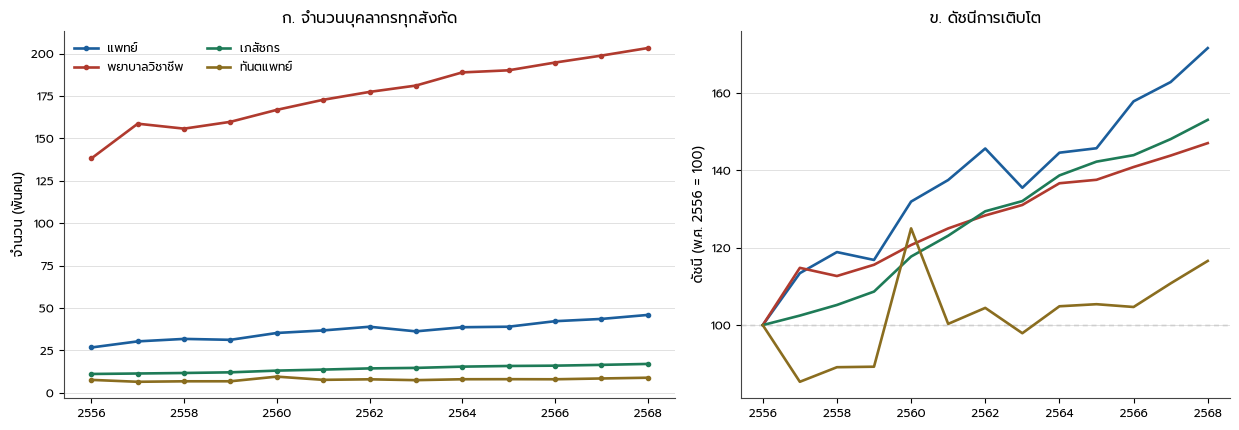

In [4]:
fig_data = WF[WF.universe == "all_sectors"].assign(be_year=lambda d: d.year + C.BE)
display(fig_data.pivot(index="year", columns="cadre", values="headcount"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axes[0]
for c in CAD:
    s = fig_data[fig_data.cadre == c]
    ax.plot(s.year, s.headcount / 1000, marker="o", ms=3, lw=1.9, color=R.CADRE_COLOR[c], label=c)
ax.set_ylabel("จำนวน (พันคน)")
ax.set_title("ก. จำนวนบุคลากรทุกสังกัด")
R.be_ticks(ax, C.YEARS)
ax.grid(**R.GRID_KW)
ax.legend(frameon=False, ncol=2)
ax = axes[1]
for c in CAD:
    s = fig_data[fig_data.cadre == c]
    ax.plot(s.year, 100 * s.headcount / s.headcount.iloc[0], lw=1.9, color=R.CADRE_COLOR[c], label=c)
ax.axhline(100, **R.REFLINE_KW)
ax.set_ylabel(f"ดัชนี (พ.ศ. {C.be(Y0)} = 100)")
ax.set_title("ข. ดัชนีการเติบโต")
R.be_ticks(ax, C.YEARS)
ax.grid(**R.GRID_KW)
fig.tight_layout()
S.figure("F41_WORKFORCE_COUNTS", fig, fig_data, "จำนวนบุคลากร 4 วิชาชีพ ทุกสังกัด พ.ศ. 2556–2568", main=True)
plt.show()

### ดัชนีการเติบโตแยกสังกัด (พ.ศ. 2556 = 100)
ดัชนี = 100 × จำนวนปีนั้น ÷ จำนวนปี 2556 ของวิชาชีพ-สังกัดเดียวกัน พยาบาลวิชาชีพรวมพยาบาลเทคนิคตามนิยามของหัวข้อ 4.1 ทันตแพทย์เอกชนมีรอยต่อของการรายงานระหว่างปี 2556–2557 และ 2560 ดัชนีจึงสะท้อนความครอบคลุมของการรายงานเป็นหลัก

year,cadre,universe,universe_th,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,แพทย์,all_sectors,ทุกสังกัด,100.0,113.4,118.9,116.8,131.9,137.5,145.7,135.5,144.6,145.7,157.8,162.8,171.6
1,แพทย์,public_total,ภาครัฐรวม,100.0,111.3,116.9,111.4,130.5,134.8,142.5,128.4,138.7,140.3,151.7,156.3,165.1
2,แพทย์,moph,กระทรวงสาธารณสุข,100.0,111.8,115.6,112.3,128.7,135.5,142.2,122.3,133.7,136.4,143.5,144.0,152.4
3,แพทย์,other_public,ภาครัฐอื่น ๆ,100.0,110.0,120.2,109.2,135.2,133.3,143.4,143.8,151.3,150.0,172.4,187.2,197.1
4,แพทย์,private,เอกชน,100.0,123.1,127.7,135.7,138.2,149.6,159.9,167.6,171.1,170.3,185.7,192.5,201.0
5,พยาบาลวิชาชีพ,all_sectors,ทุกสังกัด,100.0,114.8,112.7,115.6,120.7,125.0,128.3,131.1,136.7,137.6,140.9,143.8,147.0
6,พยาบาลวิชาชีพ,public_total,ภาครัฐรวม,100.0,114.0,111.3,111.5,117.2,120.5,123.4,124.4,131.7,132.0,133.3,135.6,138.9
7,พยาบาลวิชาชีพ,moph,กระทรวงสาธารณสุข,100.0,115.5,111.1,112.9,114.6,117.7,121.1,121.3,129.3,130.0,126.1,125.8,127.4
8,พยาบาลวิชาชีพ,other_public,ภาครัฐอื่น ๆ,100.0,108.2,112.1,106.3,127.2,131.0,132.1,136.2,140.4,139.5,160.7,172.8,182.3
9,พยาบาลวิชาชีพ,private,เอกชน,100.0,121.8,124.2,142.5,150.3,162.7,170.3,187.3,179.1,184.6,204.4,213.4,216.0


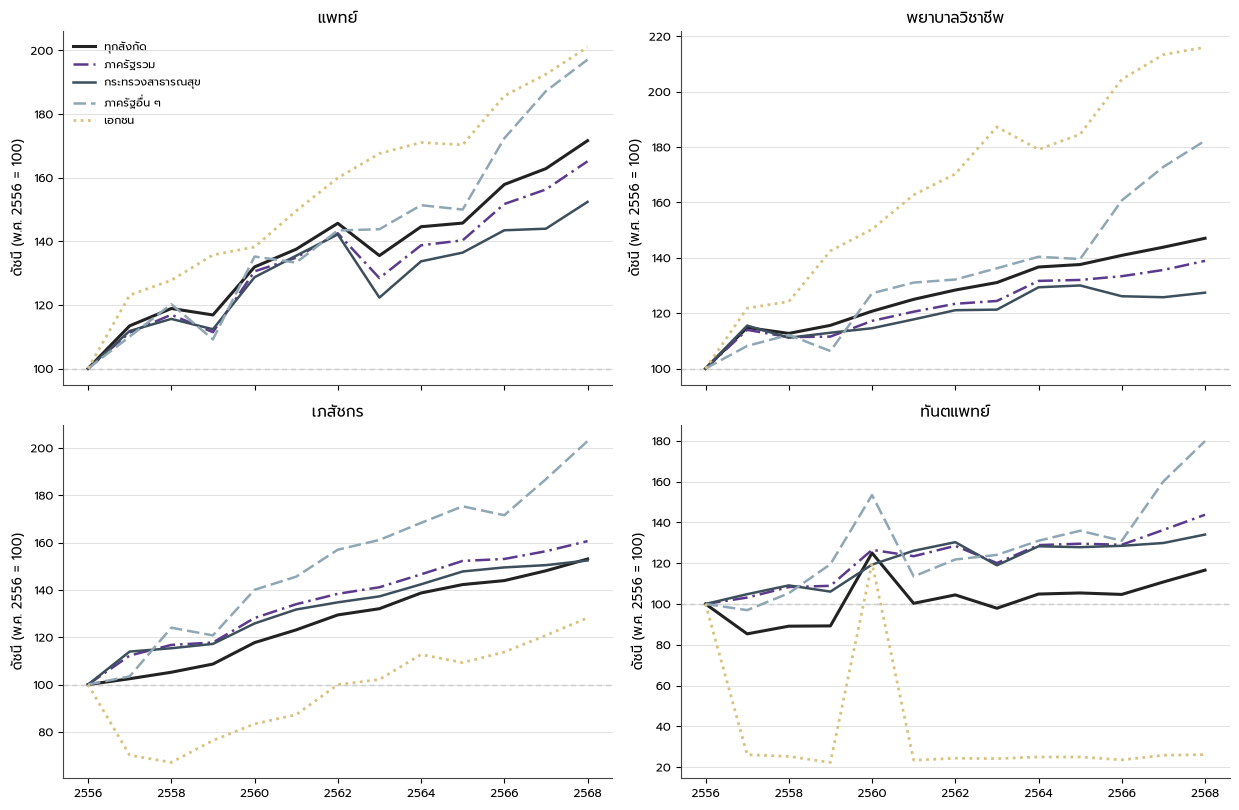

In [5]:
IDX_UNI = ["all_sectors", "public_total", "moph", "other_public", "private"]
WF_INDEX = WF[WF.universe.isin(IDX_UNI)].copy()
_base = WF_INDEX[WF_INDEX.year == Y0].set_index(["cadre", "universe"]).headcount
WF_INDEX["index_2013"] = 100 * WF_INDEX.headcount / WF_INDEX.set_index(["cadre", "universe"]).index.map(_base).to_numpy()
WF_INDEX["universe_th"] = WF_INDEX.universe.map(SEC_TH)
WF_INDEX_WIDE = (WF_INDEX.pivot_table(index=["cadre", "universe"], columns="year", values="index_2013")
                 .reindex(pd.MultiIndex.from_product([CAD, IDX_UNI], names=["cadre", "universe"])).reset_index())
WF_INDEX_WIDE.insert(2, "universe_th", WF_INDEX_WIDE.universe.map(SEC_TH))
S.table("T41_WORKFORCE_INDEX_BY_SECTOR", WF_INDEX_WIDE, "ดัชนีจำนวนบุคลากรแยกวิชาชีพและสังกัด (พ.ศ. 2556 = 100)", main=True)
display(WF_INDEX_WIDE.round(1))

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), sharex=True)
_style = {"all_sectors": ("#222222", "-", 2.2), "public_total": ("#5b3a8e", (0, (6, 2, 1, 2)), 1.8),
          "moph": (R.SECTOR_COLOR["moph"], "-", 1.8), "other_public": (R.SECTOR_COLOR["other_public"], (0, (5, 2)), 1.8),
          "private": (R.SECTOR_COLOR["private"], (0, (1, 1.6)), 2.0)}
for ax, c in zip(axes.ravel(), CAD):
    for u in IDX_UNI:
        z = WF_INDEX[(WF_INDEX.cadre == c) & (WF_INDEX.universe == u)].sort_values("year")
        col, ls, lw = _style[u]
        ax.plot(z.year, z.index_2013, color=col, ls=ls, lw=lw, label=SEC_TH[u])
    ax.axhline(100, **R.REFLINE_KW); ax.set_title(c); R.be_ticks(ax, C.YEARS); ax.grid(**R.GRID_KW)
    ax.set_ylabel(f"ดัชนี (พ.ศ. {C.be(Y0)} = 100)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F41_WORKFORCE_INDEX_BY_SECTOR", fig, WF_INDEX, "ดัชนีการเติบโตของบุคลากร 4 วิชาชีพ แยกสังกัด พ.ศ. 2556–2568 (2556 = 100)", main=True)
plt.show()

## 3. การเติบโตแยกสังกัด และส่วนต่อการเพิ่มขึ้นสุทธิ

สังกัดที่โตเร็วที่สุดอาจไม่ใช่สังกัดที่เพิ่มคนมากที่สุด เพราะฐานตั้งต้นต่างกัน การแยกส่วนต่อการเปลี่ยนแปลงสุทธิ
คือ $\Delta W_s / \sum_s \Delta W_s$ — ค่าติดลบ หรือเกินร้อยละ 100 เกิดได้จริงเมื่อบางสังกัดลดลง
จึงแสดงเป็นแท่งสองทิศ ไม่ใช้แผนภูมิซ้อนที่ซ่อนค่าติดลบ

In [6]:
contrib = []
for c in CAD:
    z = WF[(WF.cadre == c) & WF.universe.isin(["moph", "other_public", "private"])]
    a = z[z.year == Y0].set_index("universe").headcount
    b = z[z.year == Y1].set_index("universe").headcount
    t = M.contributions(a, b).reset_index().rename(columns={"universe": "sector"})
    t["cadre"] = c
    contrib.append(t)
CONTRIB = pd.concat(contrib, ignore_index=True)
CONTRIB["sector_th"] = CONTRIB.sector.map(SEC_TH)
S.table("T41_SECTOR_CONTRIBUTIONS", CONTRIB, "ส่วนของแต่ละสังกัดต่อการเปลี่ยนแปลงสุทธิ 2556–2568", main=True)
display(CONTRIB.pivot_table(index="cadre", columns="sector", values=["delta", "share_of_net_change_pct"]).round(2))
for _, r in CONTRIB.iterrows():
    en = C.CADRE_EN[r.cadre]
    S.claim(f"c41_{en}_delta_{r.sector}", r.delta, "int", "คน", "T41_SECTOR_CONTRIBUTIONS", f"cadre={r.cadre},sector={r.sector}", "delta")
    S.claim(f"c41_{en}_share_{r.sector}", r.share_of_net_change_pct, "{:.2f}", "%", "T41_SECTOR_CONTRIBUTIONS", f"cadre={r.cadre},sector={r.sector}", "share_of_net_change_pct")
# the largest contributor per cadre, computed not asserted
top = CONTRIB.loc[CONTRIB.groupby("cadre").delta.idxmax()][["cadre", "sector"]]
S.text_claim("c41_top_contributor_all_moph", "ใช่" if (top.sector == "moph").all() else "ไม่ใช่",
             note="ทุกวิชาชีพมี สธ. เป็นผู้มีส่วนต่อการเพิ่มขึ้นสุทธิมากที่สุดหรือไม่")

delta                       share_of_net_change_pct                     
sector            moph other_public  private                    moph other_public private
cadre                                                                                    
ทันตแพทย์       1581.0        999.0  -1308.0                  124.29        78.54 -102.83
พยาบาลวิชาชีพ  26776.0      21279.0  16964.0                   41.18        32.73   26.09
เภสัชกร         3761.0       1426.0    730.0                   63.56        24.10   12.34
แพทย์           8210.0       6074.0   4886.0                   42.83        31.68   25.49

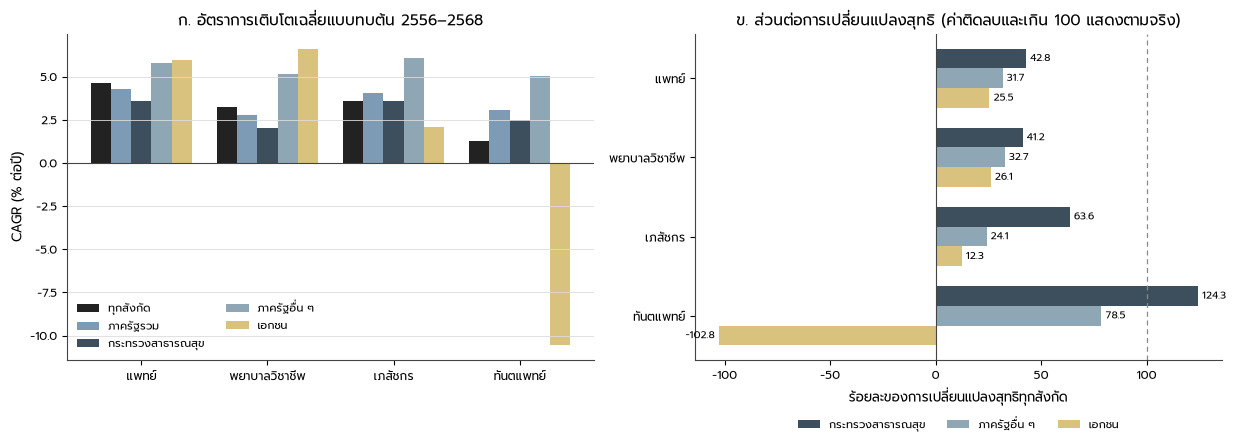

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
sub = END[END.universe.isin(["all_sectors", "public_total", "moph", "other_public", "private"])]
order = ["all_sectors", "public_total", "moph", "other_public", "private"]
w = 0.16
for i, u in enumerate(order):
    v = sub[sub.universe == u].set_index("cadre").reindex(CAD).cagr_pct
    ax.bar(np.arange(4) + (i - 2) * w, v, width=w, label=SEC_TH[u],
           color=["#222222", "#7d9bb4", R.SECTOR_COLOR["moph"], R.SECTOR_COLOR["other_public"], R.SECTOR_COLOR["private"]][i])
ax.axhline(0, color="#444", lw=0.8)
ax.set_xticks(range(4)); ax.set_xticklabels(CAD)
ax.set_ylabel("CAGR (% ต่อปี)"); ax.set_title("ก. อัตราการเติบโตเฉลี่ยแบบทบต้น 2556–2568")
ax.legend(frameon=False, fontsize=8, ncol=2); ax.grid(**R.GRID_KW)
ax = axes[1]
for i, s in enumerate(["moph", "other_public", "private"]):
    v = CONTRIB[CONTRIB.sector == s].set_index("cadre").reindex(CAD).share_of_net_change_pct
    ax.barh(np.arange(4) + (i - 1) * 0.25, v, height=0.25, color=R.SECTOR_COLOR[s], label=SEC_TH[s])
    for y, x in zip(np.arange(4) + (i - 1) * 0.25, v):
        ax.annotate(f"{x:,.1f}", (x, y), xytext=(3 if x >= 0 else -3, 0), textcoords="offset points",
                    va="center", ha="left" if x >= 0 else "right", fontsize=7.5)
ax.axvline(0, color="#444", lw=0.8); ax.axvline(100, **R.REFLINE_KW)
ax.set_yticks(range(4)); ax.set_yticklabels(CAD); ax.invert_yaxis()
ax.set_xlabel("ร้อยละของการเปลี่ยนแปลงสุทธิทุกสังกัด"); ax.set_title("ข. ส่วนต่อการเปลี่ยนแปลงสุทธิ (ค่าติดลบและเกิน 100 แสดงตามจริง)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
fig.tight_layout()
S.figure("F41_SECTOR_GROWTH_CONTRIB", fig, pd.concat([sub.assign(panel="A"), CONTRIB.assign(panel="B")]),
         "อัตราการเติบโตแยกสังกัด และส่วนต่อการเปลี่ยนแปลงสุทธิ 2556–2568", main=True)
plt.show()

## 4. ความไม่ต่อเนื่องของการรายงาน: การเปลี่ยนสังกัดไม่ใช่การออกจากระบบ

* ปี 2566: การถ่ายโอน รพ.สต. ไปองค์กรปกครองส่วนท้องถิ่น — พยาบาลวิชาชีพสังกัด สธ. ลดลงพร้อมกับภาครัฐอื่นเพิ่มขึ้น
* ทันตแพทย์ภาคเอกชน: ระดับที่รายงานลดลงมาก ซึ่งน่าจะเป็นความครอบคลุมของการรายงาน
* แพทย์ สธ. ปี 2563: ต่ำกว่าปีข้างเคียงขณะที่ยอดรวมทุกสังกัดไม่เคลื่อนตาม

In [8]:
def yoy_table(cadre, years):
    z = WF[(WF.cadre == cadre) & WF.universe.isin(["moph", "other_public", "private", "all_sectors"])]
    p = z.pivot_table(index="year", columns="universe", values="headcount")
    return p.diff().loc[years]

tr = yoy_table("พยาบาลวิชาชีพ", [2022, 2023, 2024])
display(tr)
S.table("T41_TRANSFER_2023_NURSES", tr.reset_index(), "การเปลี่ยนแปลงรายปีของพยาบาลวิชาชีพรอบการถ่ายโอน รพ.สต.")
S.claim("c41_nurse_2023_moph_change", tr.loc[2023, "moph"], "int", "คน", "T41_TRANSFER_2023_NURSES")
S.claim("c41_nurse_2023_other_public_change", tr.loc[2023, "other_public"], "int", "คน")
S.claim("c41_nurse_2023_total_change", tr.loc[2023, "all_sectors"], "int", "คน")
dp = WF[(WF.cadre == "ทันตแพทย์") & (WF.universe == "private")].set_index("year").headcount
display(dp.to_frame("private_dentists").T)
S.claim("c41_dent_private_2013", dp[Y0], "int", "คน")
S.claim("c41_dent_private_2025", dp[Y1], "int", "คน")
S.claim("c41_dent_private_2014", dp[2014], "int", "คน")
mp = WF[(WF.cadre == "แพทย์")].pivot_table(index="year", columns="universe", values="headcount").loc[2018:2022]
display(mp)
S.table("T41_PHYSICIAN_2020_DIP", mp.reset_index(), "แพทย์ สธ. ปี 2563 เทียบปีข้างเคียง")
# dentist contribution sensitivity: excluding the private series entirely
ds = CONTRIB[CONTRIB.cadre == "ทันตแพทย์"].set_index("sector")
pub_only = ds.loc[["moph", "other_public"], "delta"]
S.claim("c41_dent_public_delta", pub_only.sum(), "int", "คน", note="การเพิ่มขึ้นสุทธิเฉพาะภาครัฐ (ไม่รวมชุดเอกชนที่ไม่ต่อเนื่อง)")
S.claim("c41_dent_moph_share_public_only", 100 * pub_only["moph"] / pub_only.sum(), "{:.2f}", "%")

universe,all_sectors,moph,other_public,private
year,,,,
2022,1238.0,641.0,-210.0,807.0
2023,4562.0,-3806.0,5473.0,2895.0
2024,4096.0,-347.0,3134.0,1309.0


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
private_dentists,1771.0,462.0,447.0,395.0,2124.0,414.0,431.0,428.0,442.0,442.0,417.0,457.0,463.0


universe,all_sectors,moph,other_public,private,public_total
year,,,,,
2018,36807.0,21232.0,8339.0,7236.0,29571.0
2019,38988.0,22281.0,8971.0,7736.0,31252.0
2020,36270.0,19168.0,8995.0,8107.0,28163.0
2021,38698.0,20954.0,9468.0,8276.0,30422.0
2022,39005.0,21384.0,9382.0,8239.0,30766.0


61.27906976744186

## 5. บริการ: ขอบเขตสองชุดที่ต้องไม่ปนกัน

* `all_reporting` = สถานพยาบาลที่รายงานในตารางที่ 4 (กว้างกว่าโรงพยาบาล สธ.)
* `moph_service` = โรงพยาบาลศูนย์ + ทั่วไป + ชุมชน สังกัด สธ. (ตารางที่ 5–7) — ไม่รวม รพ.สต.

ตรวจก่อนว่าชุด สธ. ซ้อนอยู่ภายในชุดทั้งหมดในระดับประเทศทุกปี

In [9]:
nest = aud["service_nesting"]
display(nest[nest.metric.isin(["op_visits", "ip_admissions", "ip_days", "op_persons"])].pivot(
    index="year", columns="metric", values="moph_share_pct").round(2))
assert (nest.moph_service <= nest.all_reporting).all()
S.table("T41_SERVICE_NESTING", nest, "สัดส่วนบริการของโรงพยาบาล สธ. ในบริการทั้งหมดที่รายงาน")
S.table("T41_SERVICE_NESTING_PROVINCE_ANOMALIES", aud["service_nesting_province_anomalies"],
        "จังหวัด-ปีที่ชุด สธ. สูงกว่าชุดทั้งหมด (ความไม่สอดคล้องของแหล่ง ไม่ได้แก้ค่า)")

SV = pd.concat([P.services_national("all_reporting"), P.services_national("moph_service")], ignore_index=True)
SV = SV[SV.metric.isin(["op_visits", "op_persons", "ip_admissions", "ip_days", "beds"])]
S.table("T41_SERVICES_ANNUAL", SV.pivot_table(index=["tier", "metric"], columns="year", values="value").reset_index(),
        "ปริมาณบริการรายปี แยกขอบเขต")
SE = M.endpoint_summary(SV, ["tier", "metric"], y0=Y0, y1=Y1)
SE_short = M.endpoint_summary(SV, ["tier", "metric"], y0=FY0, y1=Y1).assign(window="2018-2025")
S.table("T41_SERVICES_ENDPOINTS", pd.concat([SE.assign(window="2013-2025"), SE_short]),
        "บริการต้นช่วง ปลายช่วง และ CAGR ช่วงยาวและช่วงร่วมกับ case-mix", main=True)
display(SE.pivot_table(index="metric", columns="tier", values=["value_start", "value_end", "cagr_pct"]).round(2))
for _, r in SE.iterrows():
    tag = f"{r.tier}_{r.metric}"
    S.claim(f"c41_{tag}_start", r.value_start, "int", "", "T41_SERVICES_ENDPOINTS")
    S.claim(f"c41_{tag}_end", r.value_end, "int", "", "T41_SERVICES_ENDPOINTS")
    S.claim(f"c41_{tag}_cagr", r.cagr_pct, "{:.2f}", "% ต่อปี", "T41_SERVICES_ENDPOINTS")
    S.claim(f"c41_{tag}_pct", r["pct_change"], "{:.2f}", "%", "T41_SERVICES_ENDPOINTS")

# MOPH hospitals' share of the net increase, and their share of volume at both ends
sh = []
for m in ["op_visits", "ip_admissions", "ip_days", "op_persons"]:
    a = SV[(SV.metric == m)].pivot(index="year", columns="tier", values="value")
    sh.append(dict(metric=m, moph_share_of_net_increase_pct=100 * (a.moph_service[Y1] - a.moph_service[Y0]) / (a.all_reporting[Y1] - a.all_reporting[Y0]),
                   moph_share_start_pct=100 * a.moph_service[Y0] / a.all_reporting[Y0],
                   moph_share_end_pct=100 * a.moph_service[Y1] / a.all_reporting[Y1]))
SH = pd.DataFrame(sh)
S.table("T41_MOPH_SERVICE_SHARE", SH, "ส่วนของโรงพยาบาล สธ. ต่อการเพิ่มขึ้นสุทธิของบริการ และสัดส่วนปริมาณบริการ", main=True)
display(SH.round(2))
for _, r in SH.iterrows():
    S.claim(f"c41_moph_netshare_{r.metric}", r.moph_share_of_net_increase_pct, "{:.2f}", "%", "T41_MOPH_SERVICE_SHARE")
    S.claim(f"c41_moph_share_start_{r.metric}", r.moph_share_start_pct, "{:.2f}", "%")
    S.claim(f"c41_moph_share_end_{r.metric}", r.moph_share_end_pct, "{:.2f}", "%")

# COVID-period inpatient-day spike: year-on-year change in the long series
ipd = SV[(SV.metric == "ip_days")].pivot(index="year", columns="tier", values="value")
S.table("T41_IPDAYS_ANNUAL", ipd.reset_index(), "วันนอนรวมรายปี (สังเกตช่วงโควิด-19)")

metric,ip_admissions,ip_days,op_persons,op_visits
year,,,,
2013,66.17,65.12,71.72,61.17
2014,63.73,63.86,71.80,59.41
2015,65.91,67.19,68.57,64.38
2016,72.01,69.64,72.07,66.17
2017,66.96,64.61,67.41,59.42
2018,69.32,67.06,70.34,62.37
2019,66.71,65.37,65.17,59.75
2020,67.32,65.31,66.99,59.73
2021,68.85,68.65,69.50,61.76


cagr_pct                  value_end                value_start             
tier          all_reporting moph_service all_reporting moph_service all_reporting moph_service
metric                                                                                        
beds                   1.30         1.71      176785.0     104760.0      151328.0      85468.0
ip_admissions          1.30         1.67    11384968.0    7866029.0     9744624.0    6448280.0
ip_days                1.47         1.94    47066984.0   32388429.0    39484400.0   25713080.0
op_persons             2.55         0.51    56435277.0   31823934.0    41741356.0   29936812.0
op_visits              2.31         1.60   239428021.0  134722070.0   182128940.0  111400009.0

,metric,moph_share_of_net_increase_pct,moph_share_start_pct,moph_share_end_pct
0,op_visits,40.70,61.17,56.27
1,ip_admissions,86.43,66.17,69.09
2,ip_days,88.04,65.12,68.81
3,op_persons,12.84,71.72,56.39


tier,year,all_reporting,moph_service
0,2013,39484400.0,25713080.0
1,2014,40676937.0,25974271.0
2,2015,38471162.0,25850294.0
3,2016,39499832.0,27507251.0
4,2017,41586284.0,26869163.0
5,2018,41431245.0,27785541.0
6,2019,43120126.0,28185754.0
7,2020,41328188.0,26992772.0
8,2021,48174249.0,33073667.0
9,2022,57825869.0,39945500.0


## 6. ผู้ป่วยนอก: จำนวนครั้ง = จำนวนคนที่รายงาน × ครั้งต่อคน

จำนวน "คน" ที่รายงานเป็นการนับของแต่ละสถานพยาบาล — คนเดียวที่ไปหลายแห่งถูกนับซ้ำ จึงลดการนับซ้ำได้
เฉพาะภายในสถานพยาบาลเดียว การแยกองค์ประกอบใช้เอกลักษณ์ $\ln V=\ln N+\ln(V/N)$ บนขอบเขตเดียวกัน

In [10]:
dec = []
for tier in ["all_reporting", "moph_service"]:
    a = SV[(SV.tier == tier)].pivot(index="year", columns="metric", values="value")
    r = M.op_decomposition(a.op_visits[Y0], a.op_visits[Y1], a.op_persons[Y0], a.op_persons[Y1], Y1 - Y0)
    r["tier"] = tier
    dec.append(r)
    for k_, v in r.items():
        if k_ != "tier":
            S.claim(f"c41_opdec_{tier}_{k_}", v, "{:.2f}", "", "T41_OP_DECOMPOSITION")
DEC = pd.DataFrame(dec)
assert DEC.identity_residual.abs().max() < 1e-12
S.table("T41_OP_DECOMPOSITION", DEC, "แยกการเปลี่ยนแปลงของครั้งผู้ป่วยนอกเป็นจำนวนคนที่รายงาน และครั้งต่อคน 2556–2568", main=True)
display(DEC.round(3))

opp = SV[SV.metric.isin(["op_persons", "op_visits"])].pivot_table(index="year", columns=["tier", "metric"], values="value")
yo = 100 * opp.pct_change()
display(yo.loc[2022:2025].round(2))
S.table("T41_OP_PERSONS_YOY", yo.reset_index().set_axis(["year"] + [f"{a}__{b}" for a, b in yo.columns], axis=1),
        "การเปลี่ยนแปลงรายปี (%) ของจำนวนผู้ป่วยนอก (คน) และครั้ง แยกขอบเขต")
S.claim("c41_op_persons_all_yoy_2023", yo.loc[2023, ("all_reporting", "op_persons")], "{:.2f}", "%")
S.claim("c41_op_persons_moph_yoy_2023", yo.loc[2023, ("moph_service", "op_persons")], "{:.2f}", "%")
nonmoph = opp[("all_reporting", "op_persons")] - opp[("moph_service", "op_persons")]
S.claim("c41_op_persons_nonmoph_yoy_2023", 100 * (nonmoph[2023] / nonmoph[2022] - 1), "{:.2f}", "%",
        note="ส่วนที่อยู่นอกโรงพยาบาล สธ. ในตารางที่ 4")

,freq_start,freq_end,visits_pct,persons_pct,freq_pct,cagr_visits_pct,cagr_persons_pct,cagr_freq_pct,share_from_persons_pct,share_from_frequency_pct,identity_residual,tier
0,4.363,4.243,31.461,35.202,-2.767,2.306,2.545,-0.234,110.260,-10.260,0.0,all_reporting
1,3.721,4.233,20.935,6.304,13.764,1.597,0.511,1.080,32.159,67.841,-0.0,moph_service


tier   all_reporting           moph_service          
metric    op_persons op_visits   op_persons op_visits
year                                                 
2022           10.23     18.17        12.86     19.75
2023           26.06    -14.39        -3.98    -23.92
2024           -6.79      2.29        -0.41      2.16
2025            1.20      5.96        -1.46      7.33

100.19163769684671

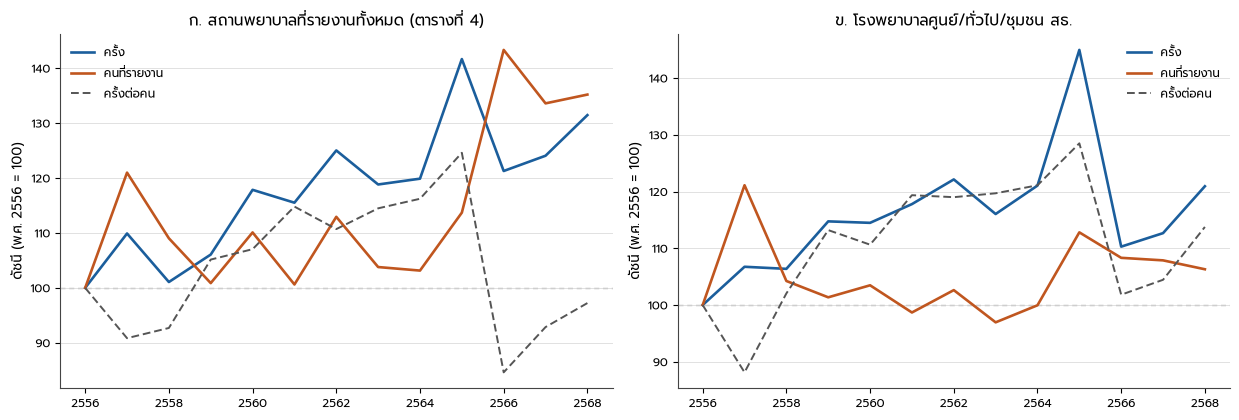

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=False)
for ax, tier, title in zip(axes, ["all_reporting", "moph_service"],
                           ["ก. สถานพยาบาลที่รายงานทั้งหมด (ตารางที่ 4)", "ข. โรงพยาบาลศูนย์/ทั่วไป/ชุมชน สธ."]):
    a = SV[(SV.tier == tier)].pivot(index="year", columns="metric", values="value")
    for m, col, lab in [("op_visits", "#1b5e9c", "ครั้ง"), ("op_persons", "#c0561f", "คนที่รายงาน")]:
        ax.plot(a.index, 100 * a[m] / a[m][Y0], color=col, lw=1.9, label=lab)
    f = a.op_visits / a.op_persons
    ax.plot(a.index, 100 * f / f[Y0], color="#555", lw=1.4, ls=(0, (4, 2)), label="ครั้งต่อคน")
    ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, C.YEARS); ax.grid(**R.GRID_KW)
    ax.set_title(title); ax.set_ylabel(f"ดัชนี (พ.ศ. {C.be(Y0)} = 100)")
    ax.legend(frameon=False)
fig.tight_layout()
opp_flat = opp.copy(); opp_flat.columns = [f"{a}__{b}" for a, b in opp.columns]
S.figure("F41_OP_PERSONS_FREQUENCY", fig, opp_flat.reset_index().melt(id_vars="year"),
         "ครั้งผู้ป่วยนอก จำนวนคนที่รายงาน และครั้งต่อคน แยกขอบเขต", main=True)
plt.show()

## 7. ผู้ป่วยในและน้ำหนักบริการ (case-mix, ปีงบประมาณ 2561–2568)

$CMI = \sum \text{SumAdjRW} / \sum \text{จำนวนคำนวณ}$ (อัตราส่วนของผลรวม ไม่ใช่ค่าเฉลี่ยของ CMI รายโรงพยาบาล)
และ $\text{SumAdjRW} = \text{จำนวนคำนวณ} \times CMI$ บนระเบียนชุดเดียวกัน — ไม่นำจำนวนรับไว้รักษาจากตารางอื่นมาแทน

In [12]:
cm = load("casemix_hospital").groupby("fiscal_year").agg(
    hospitals=("hospital_code", "nunique"), cases=("cases_calculated", "sum"), ip_days=("ip_days", "sum"),
    sum_adjrw=("sum_adjrw", "sum"), beds=("beds", "sum")).reset_index()
cm["cmi"] = cm.sum_adjrw / cm.cases
cm["alos"] = cm.ip_days / cm.cases
cm["identity_gap"] = cm.sum_adjrw - cm.cases * cm.cmi
assert cm.identity_gap.abs().max() < 1e-6
cm["log_adjrw_change"] = np.log(cm.sum_adjrw / cm.sum_adjrw.iloc[0])
cm["log_cases_change"] = np.log(cm.cases / cm.cases.iloc[0])
cm["log_cmi_change"] = np.log(cm.cmi / cm.cmi.iloc[0])
cm["cmi_yoy_pct"] = 100 * cm.cmi.pct_change()
S.table("T41_CASEMIX_NATIONAL", cm, "ผลรวม AdjRW จำนวนคำนวณ CMI และวันนอนเฉลี่ย โรงพยาบาล สธ. ที่ส่งข้อมูล (ปีงบประมาณ)", main=True)
display(cm.round(4))
a, b = cm.iloc[0], cm.iloc[-1]
S.claim("c41_adjrw_start", a.sum_adjrw, "int", "AdjRW", "T41_CASEMIX_NATIONAL")
S.claim("c41_adjrw_end", b.sum_adjrw, "int", "AdjRW")
S.claim("c41_adjrw_pct", M.pct_change(a.sum_adjrw, b.sum_adjrw), "{:.2f}", "%")
S.claim("c41_cmi_start", a.cmi, "{:.4f}", "")
S.claim("c41_cmi_end", b.cmi, "{:.4f}", "")
S.claim("c41_cmi_pct", M.pct_change(a.cmi, b.cmi), "{:.2f}", "%")
S.claim("c41_cases_pct", M.pct_change(a.cases, b.cases), "{:.2f}", "%")
S.claim("c41_casemix_share_from_cmi", 100 * b.log_cmi_change / b.log_adjrw_change, "{:.1f}", "%",
        note="ส่วนของ log-change ของ SumAdjRW ที่มาจาก CMI (ส่วนที่เหลือมาจากจำนวนคำนวณ)")
S.claim("c41_cmi_yoy_2023", cm.set_index("fiscal_year").cmi_yoy_pct[2023], "{:.2f}", "%")
S.claim("c41_cmi_max_other_yoy", cm.set_index("fiscal_year").cmi_yoy_pct.drop(2023).abs().max(), "{:.2f}", "%")
S.claim("c41_casemix_hosp_first", a.hospitals, "int", "แห่ง")
S.claim("c41_casemix_hosp_last", b.hospitals, "int", "แห่ง")
S.claim("c41_alos_start", a.alos, "{:.2f}", "วัน")
S.claim("c41_alos_end", b.alos, "{:.2f}", "วัน")

,fiscal_year,hospitals,cases,ip_days,sum_adjrw,beds,cmi,alos,identity_gap,log_adjrw_change,log_cases_change,log_cmi_change,cmi_yoy_pct
0,2018,866,7104977,30417970,7.908236e+06,90345,1.1131,4.2812,0.0,0.0000,0.0000,0.0000,NaN
1,2019,872,7206150,28669808,8.183400e+06,94883,1.1356,3.9785,0.0,0.0342,0.0141,0.0201,2.0266
2,2020,870,6673210,26865430,7.993874e+06,96921,1.1979,4.0259,0.0,0.0108,-0.0627,0.0735,5.4853
3,2021,880,6499391,30751808,8.211828e+06,99350,1.2635,4.7315,0.0,0.0377,-0.0891,0.1268,5.4738
4,2022,882,7868746,42618857,9.179232e+06,100962,1.1665,5.4162,0.0,0.1490,0.1021,0.0469,-7.6719
5,2023,888,7328764,29670683,9.611392e+06,101900,1.3115,4.0485,0.0,0.1950,0.0310,0.1640,12.4229
6,2024,893,7944091,31505891,1.044131e+07,102239,1.3143,3.9660,0.0,0.2779,0.1116,0.1662,0.2202
7,2025,895,8124839,32772377,1.097959e+07,104405,1.3514,4.0336,0.0,0.3281,0.1341,0.1940,2.8159


4.033603250476717

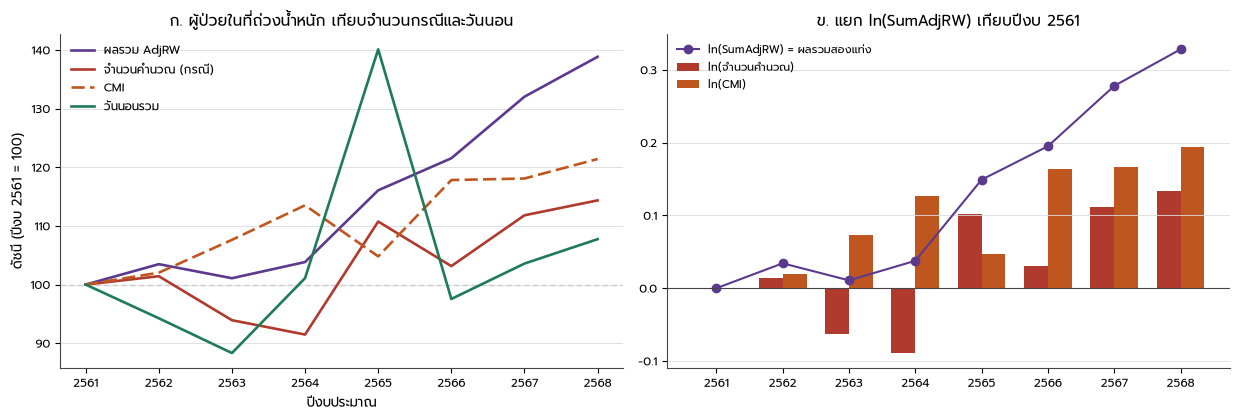

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax = axes[0]
for col, lab, c in [("sum_adjrw", "ผลรวม AdjRW", "#5b3a8e"), ("cases", "จำนวนคำนวณ (กรณี)", "#b03a2e"),
                    ("cmi", "CMI", "#c0561f"), ("ip_days", "วันนอนรวม", "#1e7b57")]:
    ax.plot(cm.fiscal_year, 100 * cm[col] / cm[col].iloc[0], lw=1.9, color=c, label=lab,
            ls="-" if col != "cmi" else (0, (5, 2)))
ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, list(range(FY0, FY1 + 1)), 1); ax.grid(**R.GRID_KW)
ax.set_xlabel("ปีงบประมาณ"); ax.set_ylabel(f"ดัชนี (ปีงบ {C.be(FY0)} = 100)")
ax.set_title("ก. ผู้ป่วยในที่ถ่วงน้ำหนัก เทียบจำนวนกรณีและวันนอน"); ax.legend(frameon=False)
ax = axes[1]
ax.bar(cm.fiscal_year - 0.18, cm.log_cases_change, width=0.36, color="#b03a2e", label="ln(จำนวนคำนวณ)")
ax.bar(cm.fiscal_year + 0.18, cm.log_cmi_change, width=0.36, color="#c0561f", label="ln(CMI)")
ax.plot(cm.fiscal_year, cm.log_adjrw_change, color="#5b3a8e", marker="o", label="ln(SumAdjRW) = ผลรวมสองแท่ง")
ax.axhline(0, color="#444", lw=0.8); R.be_ticks(ax, list(range(FY0, FY1 + 1)), 1)
ax.set_title(f"ข. แยก ln(SumAdjRW) เทียบปีงบ {C.be(FY0)}"); ax.legend(frameon=False, fontsize=8); ax.grid(**R.GRID_KW)
fig.tight_layout()
S.figure("F41_CASEMIX", fig, cm, "ผลรวม AdjRW จำนวนคำนวณ และ CMI ปีงบประมาณ 2561–2568", main=True)
plt.show()

## 8. รูปบริการ: อัตราการเติบโตและส่วนต่อการเพิ่มขึ้นสุทธิของโรงพยาบาล สธ.

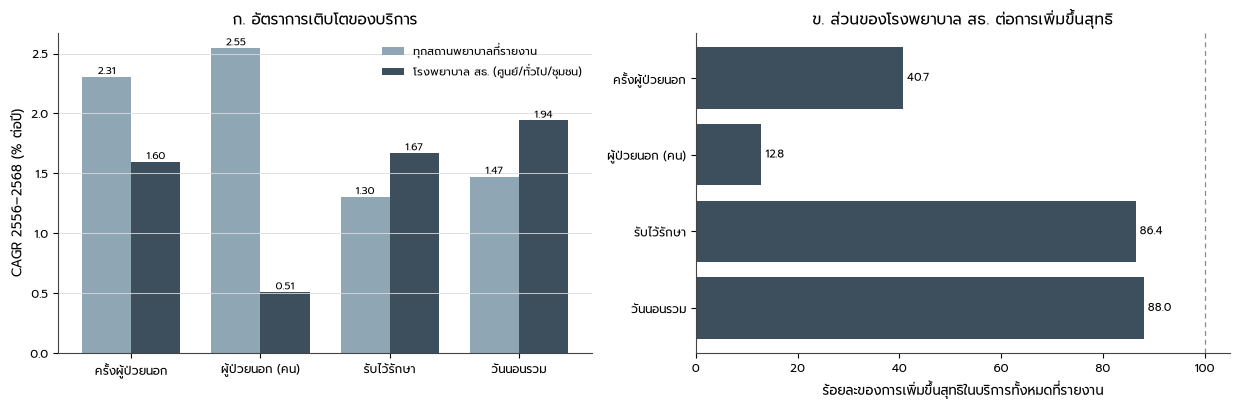

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
mets = ["op_visits", "op_persons", "ip_admissions", "ip_days"]
lab = {"op_visits": "ครั้งผู้ป่วยนอก", "op_persons": "ผู้ป่วยนอก (คน)", "ip_admissions": "รับไว้รักษา", "ip_days": "วันนอนรวม"}
for i, tier in enumerate(["all_reporting", "moph_service"]):
    v = SE[SE.tier == tier].set_index("metric").reindex(mets).cagr_pct
    ax.bar(np.arange(4) + (i - .5) * .38, v, width=.38, color=["#8fa6b4", "#3d4f5c"][i],
           label=["ทุกสถานพยาบาลที่รายงาน", "โรงพยาบาล สธ. (ศูนย์/ทั่วไป/ชุมชน)"][i])
    for x, y in zip(np.arange(4) + (i - .5) * .38, v):
        ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7.5)
ax.set_xticks(range(4)); ax.set_xticklabels([lab[m] for m in mets]); ax.set_ylabel("CAGR 2556–2568 (% ต่อปี)")
ax.legend(frameon=False, fontsize=8); ax.grid(**R.GRID_KW); ax.set_title("ก. อัตราการเติบโตของบริการ")
ax = axes[1]
v = SH.set_index("metric").reindex(mets)
ax.barh(range(4), v.moph_share_of_net_increase_pct, color="#3d4f5c")
for y, x in enumerate(v.moph_share_of_net_increase_pct):
    ax.annotate(f"{x:.1f}", (x, y), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.axvline(100, **R.REFLINE_KW)
ax.set_yticks(range(4)); ax.set_yticklabels([lab[m] for m in mets]); ax.invert_yaxis()
ax.set_xlabel("ร้อยละของการเพิ่มขึ้นสุทธิในบริการทั้งหมดที่รายงาน"); ax.set_title("ข. ส่วนของโรงพยาบาล สธ. ต่อการเพิ่มขึ้นสุทธิ")
fig.tight_layout()
S.figure("F41_SERVICE_GROWTH", fig, pd.concat([SE.assign(panel="A"), SH.assign(panel="B")]),
         "อัตราการเติบโตของบริการ และส่วนของโรงพยาบาล สธ. ต่อการเพิ่มขึ้นสุทธิ 2556–2568", main=True)
plt.show()

### ดัชนีบริการ (พ.ศ. 2556 = 100; case-mix ปีงบ 2561 = 100)
ดัชนี = 100 × ค่าปีนั้น ÷ ค่าปีฐานของตัวชี้วัดและขอบเขตเดียวกัน บริการจากรายงานทรัพยากรสาธารณสุขใช้ฐาน พ.ศ. 2556 ส่วน case-mix เป็นปีงบประมาณและเริ่มปี 2561 จึงใช้ฐานของตัวเอง ไม่นำมาต่อเข้ากับชุดยาว

year,series,tier,metric,base_year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,casemix_fiscal_year,moph_casemix,alos,2018,NaN,NaN,NaN,NaN,NaN,100.0,92.9,94.0,110.5,126.5,94.6,92.6,94.2
1,casemix_fiscal_year,moph_casemix,cases,2018,NaN,NaN,NaN,NaN,NaN,100.0,101.4,93.9,91.5,110.7,103.1,111.8,114.4
2,casemix_fiscal_year,moph_casemix,cmi,2018,NaN,NaN,NaN,NaN,NaN,100.0,102.0,107.6,113.5,104.8,117.8,118.1,121.4
3,casemix_fiscal_year,moph_casemix,ip_days,2018,NaN,NaN,NaN,NaN,NaN,100.0,94.3,88.3,101.1,140.1,97.5,103.6,107.7
4,casemix_fiscal_year,moph_casemix,sum_adjrw,2018,NaN,NaN,NaN,NaN,NaN,100.0,103.5,101.1,103.8,116.1,121.5,132.0,138.8
5,health_resource_report,all_reporting,beds,2013,100.0,99.4,99.2,93.5,99.7,98.9,104.4,109.9,110.7,113.2,113.2,115.2,116.8
6,health_resource_report,all_reporting,ip_admissions,2013,100.0,105.2,101.3,97.0,103.6,102.4,112.5,103.3,100.7,115.5,110.8,117.7,116.8
7,health_resource_report,all_reporting,ip_days,2013,100.0,103.0,97.4,100.0,105.3,104.9,109.2,104.7,122.0,146.5,114.4,118.1,119.2
8,health_resource_report,all_reporting,op_persons,2013,100.0,121.0,109.0,100.9,110.1,100.6,112.9,103.8,103.1,113.7,143.3,133.6,135.2
9,health_resource_report,all_reporting,op_visits,2013,100.0,109.9,101.1,106.1,117.9,115.5,125.0,118.8,119.9,141.7,121.3,124.1,131.5


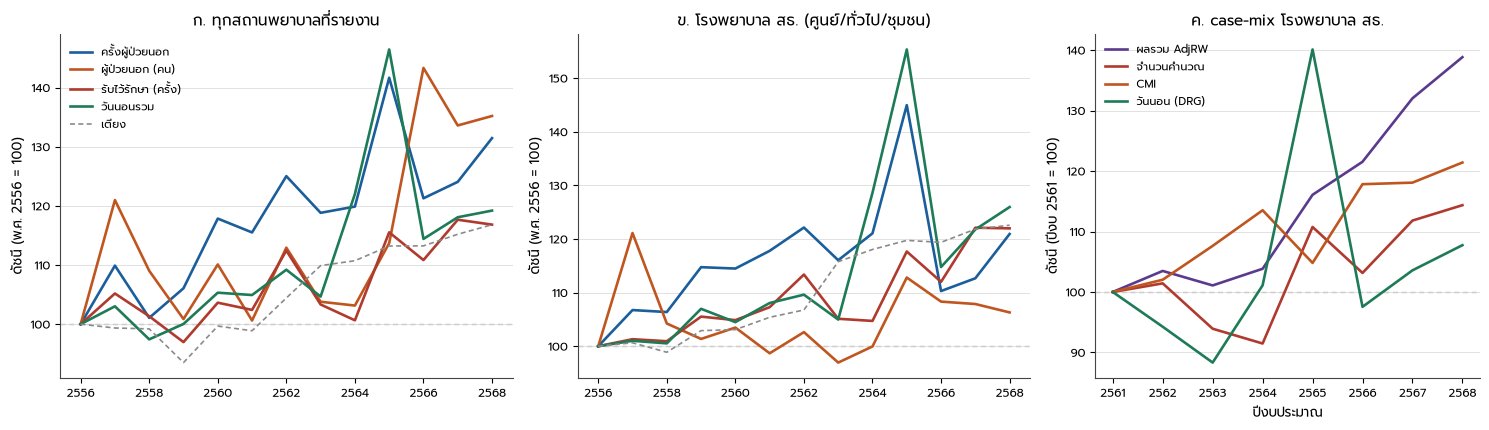

In [15]:
SVC_LAB = {"op_visits": "ครั้งผู้ป่วยนอก", "op_persons": "ผู้ป่วยนอก (คน)", "ip_admissions": "รับไว้รักษา (ครั้ง)",
           "ip_days": "วันนอนรวม", "beds": "เตียง"}
TIER_LAB = {"all_reporting": "ทุกสถานพยาบาลที่รายงาน", "moph_service": "โรงพยาบาล สธ. (ศูนย์/ทั่วไป/ชุมชน)"}
si = SV.copy()
si = si.assign(op_visits_per_person=np.nan)
_b = si[si.year == Y0].set_index(["tier", "metric"]).value
si["index"] = 100 * si.value / si.set_index(["tier", "metric"]).index.map(_b).to_numpy()
si["base_year"] = Y0
si["series"] = "health_resource_report"
freq = (SV[SV.metric.isin(["op_visits", "op_persons"])].pivot_table(index=["tier", "year"], columns="metric", values="value")
        .assign(value=lambda d: d.op_visits / d.op_persons).reset_index()[["tier", "year", "value"]].assign(metric="op_visits_per_person"))
freq["index"] = 100 * freq.value / freq.groupby("tier").value.transform(lambda s: s.iloc[0])
freq["base_year"], freq["series"] = Y0, "health_resource_report"
cmx = cm.melt(id_vars="fiscal_year", value_vars=["sum_adjrw", "cases", "cmi", "ip_days", "alos"], var_name="metric", value_name="value").rename(columns={"fiscal_year": "year"})
cmx["tier"] = "moph_casemix"
cmx["index"] = 100 * cmx.value / cmx.groupby("metric").value.transform(lambda s: s.iloc[0])
cmx["base_year"], cmx["series"] = FY0, "casemix_fiscal_year"
SVC_INDEX = pd.concat([si[["series", "tier", "metric", "year", "value", "index", "base_year"]], freq, cmx], ignore_index=True)
SVC_INDEX_WIDE = SVC_INDEX.pivot_table(index=["series", "tier", "metric", "base_year"], columns="year", values="index").reset_index()
S.table("T41_SERVICE_INDEX", SVC_INDEX_WIDE, "ดัชนีบริการแยกขอบเขต (พ.ศ. 2556 = 100; case-mix ปีงบ 2561 = 100)", main=True)
display(SVC_INDEX_WIDE.round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 0.85]))
_mc = {"op_visits": "#1b5e9c", "op_persons": "#c0561f", "ip_admissions": "#b03a2e", "ip_days": "#1e7b57", "beds": "#8a8a8a"}
for ax, tier in zip(axes[:2], ["all_reporting", "moph_service"]):
    for m, col in _mc.items():
        z = si[(si.tier == tier) & (si.metric == m)].sort_values("year")
        ax.plot(z.year, z["index"], color=col, lw=1.9 if m != "beds" else 1.2, ls="-" if m != "beds" else (0, (3, 2)), label=SVC_LAB[m])
    ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, C.YEARS, 2); ax.grid(**R.GRID_KW)
    ax.set_title(("ก. " if tier == "all_reporting" else "ข. ") + TIER_LAB[tier]); ax.set_ylabel(f"ดัชนี (พ.ศ. {C.be(Y0)} = 100)")
axes[0].legend(frameon=False, fontsize=8)
ax = axes[2]
for m, col, lab in [("sum_adjrw", "#5b3a8e", "ผลรวม AdjRW"), ("cases", "#b03a2e", "จำนวนคำนวณ"), ("cmi", "#c0561f", "CMI"), ("ip_days", "#1e7b57", "วันนอน (DRG)")]:
    z = cmx[cmx.metric == m].sort_values("year")
    ax.plot(z.year, z["index"], color=col, lw=1.9, label=lab)
ax.axhline(100, **R.REFLINE_KW); R.be_ticks(ax, list(range(FY0, FY1 + 1)), 1); ax.grid(**R.GRID_KW)
ax.set_title("ค. case-mix โรงพยาบาล สธ."); ax.set_xlabel("ปีงบประมาณ"); ax.set_ylabel(f"ดัชนี (ปีงบ {C.be(FY0)} = 100)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F41_SERVICE_INDEX", fig, SVC_INDEX, "ดัชนีบริการ พ.ศ. 2556–2568 แยกขอบเขต และ case-mix ปีงบประมาณ 2561–2568", main=True)
plt.show()

## 9. ข้อค้นพบของหัวข้อ 4.1 (คำนวณจากตารางข้างต้น)

* การเติบโตเกิดขึ้นจริงในทั้งสี่วิชาชีพ แต่เป็น **การเปลี่ยนแปลงสุทธิของจำนวนคงอยู่** ข้อมูลนี้ไม่แยกการผลิตใหม่
  การย้ายงาน การลาออก การเกษียณ หรือการเปลี่ยนสังกัด — หัวข้อ 4.4 ใช้ข้อมูลรับเข้าและสูญเสียจริงเพื่อตอบส่วนนี้
* สังกัดที่โตเร็วที่สุดไม่ใช่สังกัดที่เพิ่มคนมากที่สุด และบางสังกัดมีส่วนติดลบ (ทันตแพทย์เอกชน) ซึ่งต้องอ่านคู่กับความไม่ต่อเนื่องของการรายงาน
* บริการผู้ป่วยในที่ถ่วงน้ำหนักเพิ่มเร็วกว่าจำนวนกรณี และขั้นของ CMI ในปีงบ 2566 สอดคล้องกับการเปลี่ยนการจัดกลุ่ม/การให้รหัส
  จึงไม่ควรอ่านทั้งหมดว่าเป็นความรุนแรงที่เพิ่มขึ้น
* การเติบโตคู่ขนานของกำลังคนและบริการบอกเพียงการเปลี่ยนแปลงจากจุดตั้งต้นของแต่ละด้าน ไม่ได้บอกว่าจุดตั้งต้นเพียงพอ — จึงต้องถามต่อใน 4.2 ว่า "เทียบกับอะไร"

In [16]:
S.table("T41_AUDIT_CASEMIX_IDENTITY", aud["casemix_identity"], "ตรวจเอกลักษณ์ CMI ระดับโรงพยาบาลและจำนวนโรงพยาบาลที่ส่งไม่ครบปี")
manifest = S.finalize()
print(json_summary := {k: manifest[k] for k in ["n_tables", "n_figures", "n_claims", "seconds"]})

{'n_tables': 20, 'n_figures': 7, 'n_claims': 170, 'seconds': 5.1}
